# 3장 · 텐서플로, 파이토치, JAX 그리고 케라스

『케라스 창시자에게 배우는 딥러닝 개정 3판』 3장을 바로 돌려 보는 노트북이에요.
위에서부터 차례로 실행하면 돼요.

| 절 | 내용 | 내 필기 |
|---|---|---|
| 0 | 케라스 백엔드 고르기 | 케라스 |
| 1 | 텐서플로: 텐서 · 변수 · `GradientTape` · 선형 분류기 | tf-torch-jax, 그레이디언트 구하기 |
| 2 | 파이토치: `requires_grad` · `backward()` · `.grad` **누적** | 그레이디언트 구하기 |
| 3 | JAX: `jnp` · `jax.grad` · 상태 비저장 | 그레이디언트 구하기 |
| 4 | 케라스: 층과 모델 | 층과 모델 |
| 5 | 케라스: `compile → fit → evaluate → predict` | 설정-훈련-평가-사용 |

## 0. 케라스 백엔드 고르기 (§3.6)

케라스는 고수준이라 혼자 못 돌아요. 저수준 **백엔드**(텐서플로 · 파이토치 · JAX) 위에서 돌아요.

- `KERAS_BACKEND`는 **`import keras` 전에** 정해야 해요.
- 아무것도 안 정하면 기본은 텐서플로예요.
- 백엔드를 바꾸려면 커널을 재시작한 뒤 이 셀부터 다시 실행해요.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "jax"   # "tensorflow" / "torch" / "jax" 중 골라 보기

import numpy as np
import matplotlib.pyplot as plt

In [2]:
plt.rcParams["font.family"] = "Malgun Gothic"     # 그래프 한글 깨짐 방지 (윈도)
plt.rcParams["axes.unicode_minus"] = False

### 공통 실습 데이터: 점 구름 2개 (§3.3)

세 프레임워크로 **같은 선형 분류기**를 만들어서 비교해 볼 거예요.

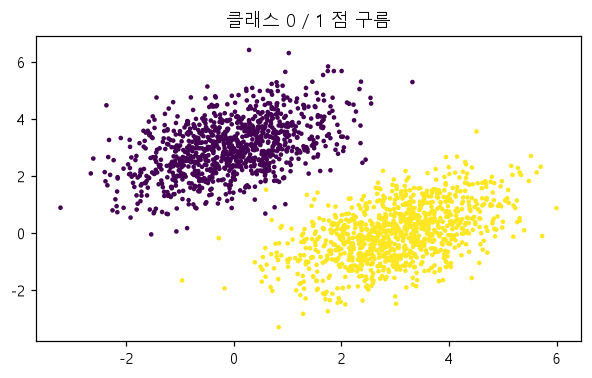

In [3]:
np.random.seed(42)            # 실행할 때마다 같은 데이터
num_samples_per_class = 1000
negative_samples = np.random.multivariate_normal(
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class)

inputs = np.vstack((negative_samples, positive_samples)).astype("float32")
targets = np.vstack((np.zeros((num_samples_per_class, 1), dtype="float32"),
                     np.ones((num_samples_per_class, 1), dtype="float32")))

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0], s=4)
plt.title("클래스 0 / 1 점 구름")
plt.show()

## 1. 텐서플로 (§3.3)

- 텐서는 **상수**라서 값 할당 불가 → 바뀌는 값은 `tf.Variable`
- `GradientTape` 블록 안의 연산을 **테이프로 기록** → `tape.gradient()`

In [4]:
import tensorflow as tf
tf.random.set_seed(42)

x = tf.ones(shape=(2, 1))
print(x)

v = tf.Variable(initial_value=tf.random.normal(shape=(3, 1)))
v[0, 0].assign(3.)          # 변수는 assign으로 바꿈
v.assign_add(tf.ones((3, 1)))
print(v)

tf.Tensor(
[[1.]
 [1.]], shape=(2, 1), dtype=float32)
<tf.Variable 'Variable:0' shape=(3, 1) dtype=float32, numpy=
array([[4.       ],
       [0.1573742],
       [1.3194337]], dtype=float32)>


In [5]:
# 그레이디언트: y = x² 를 x = 3 에서 미분 → 6
input_var = tf.Variable(initial_value=3.0)
with tf.GradientTape() as tape:
    result = tf.square(input_var)
gradient = tape.gradient(result, input_var)
print(gradient)

tf.Tensor(6.0, shape=(), dtype=float32)


In [6]:
# 선형 분류기: prediction = W·x + b, 손실 = MSE
input_dim, output_dim = 2, 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))
b = tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))

def model(inputs, W, b):
    return tf.matmul(inputs, W) + b

def mean_squared_error(targets, predictions):
    return tf.reduce_mean(tf.square(targets - predictions))

learning_rate = 0.1

@tf.function(jit_compile=True)   # 그래프 모드 + XLA 컴파일 → 빨라짐
def training_step(inputs, targets, W, b):
    with tf.GradientTape() as tape:
        predictions = model(inputs, W, b)
        loss = mean_squared_error(targets, predictions)
    grad_W, grad_b = tape.gradient(loss, [W, b])
    W.assign_sub(grad_W * learning_rate)
    b.assign_sub(grad_b * learning_rate)
    return loss

for step in range(40):
    loss = training_step(inputs, targets, W, b)
    if step % 10 == 0 or step == 39:
        print(f"스텝 {step}: 손실 {float(loss):.4f}")

스텝 0: 손실 2.5915
스텝 10: 손실 0.0773
스텝 20: 손실 0.0464
스텝 30: 손실 0.0338
스텝 39: 손실 0.0289


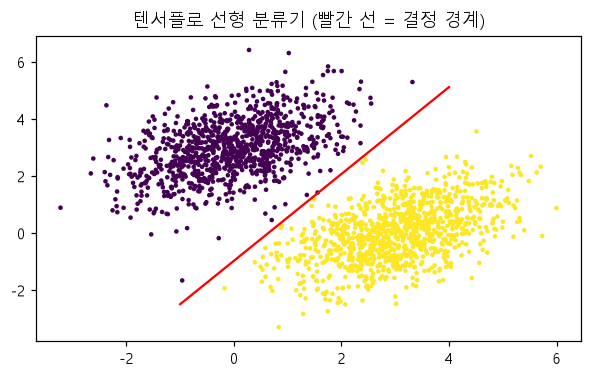

In [7]:
predictions = model(inputs, W, b)
x_line = np.linspace(-1, 4, 100)
y_line = -W[0, 0].numpy() / W[1, 0].numpy() * x_line + (0.5 - b[0].numpy()) / W[1, 0].numpy()
plt.plot(x_line, y_line, "-r")
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5, s=4)
plt.title("텐서플로 선형 분류기 (빨간 선 = 결정 경계)")
plt.show()

## 2. 파이토치 (§3.4)

- `requires_grad=True` 텐서 → `loss.backward()` → 결과는 `.grad`에 저장 (**텐서가 거꾸로 추적**)
- ⚠️ 내 필기에 빠졌던 것: `.grad`는 `backward()`할 때마다 **누적**돼요

In [8]:
import torch
torch.manual_seed(42)

input_var = torch.tensor(3.0, requires_grad=True)
result = torch.square(input_var)
result.backward()
print("1번째:", input_var.grad)    # 6

result = torch.square(input_var)
result.backward()
print("2번째:", input_var.grad)    # 12 ← 누적됨!

input_var.grad = None              # 그래서 스텝마다 비워 줘야 함

1번째: tensor(6.)
2번째: tensor(12.)


In [9]:
W = torch.rand(input_dim, output_dim, requires_grad=True)
b = torch.zeros(output_dim, requires_grad=True)
t_inputs, t_targets = torch.tensor(inputs), torch.tensor(targets)

def model(inputs, W, b):
    return torch.matmul(inputs, W) + b

def mean_squared_error(targets, predictions):
    return torch.mean(torch.square(targets - predictions))

def training_step(inputs, targets, W, b):
    predictions = model(inputs, W, b)
    loss = mean_squared_error(targets, predictions)
    loss.backward()
    with torch.no_grad():          # 업데이트는 역전파에 포함 X
        W -= W.grad * learning_rate
        b -= b.grad * learning_rate
    W.grad = None                  # 누적 방지
    b.grad = None
    return loss

for step in range(40):
    loss = training_step(t_inputs, t_targets, W, b)
    if step % 10 == 0 or step == 39:
        print(f"스텝 {step}: 손실 {loss.item():.4f}")

스텝 0: 손실 7.3616
스텝 10: 손실 0.1006
스텝 20: 손실 0.0560
스텝 30: 손실 0.0377
스텝 39: 손실 0.0307


## 3. JAX (§3.5)

- 넘파이와 **같은 API** (`jax.numpy` = `jnp`)
- **함수형 · 상태 비저장**: 손실 *함수*를 `jax.grad`에 넣으면 그레이디언트 *함수*가 나와요 (f → f′)
- 상태(W, b)는 함수 밖에서 들고 다니고, 새 값을 **반환**받아요

In [10]:
import jax
import jax.numpy as jnp

def square(x):
    return x ** 2

grad_square = jax.grad(square)     # 함수 → 도함수
print(grad_square(3.0))            # 6

6.0


In [11]:
def model(inputs, W, b):
    return jnp.matmul(inputs, W) + b

def mean_squared_error(targets, predictions):
    return jnp.mean(jnp.square(targets - predictions))

def compute_loss(state, inputs, targets):
    W, b = state
    return mean_squared_error(targets, model(inputs, W, b))

grad_fn = jax.value_and_grad(compute_loss)   # 손실과 그레이디언트를 같이

@jax.jit
def training_step(inputs, targets, W, b):
    loss, (grad_W, grad_b) = grad_fn((W, b), inputs, targets)
    W = W - grad_W * learning_rate   # 제자리 수정 X → 새 값을 반환
    b = b - grad_b * learning_rate
    return loss, W, b

W = jax.random.uniform(jax.random.key(42), shape=(input_dim, output_dim))
b = jnp.zeros(shape=(output_dim,))
for step in range(40):
    loss, W, b = training_step(inputs, targets, W, b)
    if step % 10 == 0 or step == 39:
        print(f"스텝 {step}: 손실 {float(loss):.4f}")

스텝 0: 손실 3.1345
스텝 10: 손실 0.0774
스텝 20: 손실 0.0465
스텝 30: 손실 0.0338
스텝 39: 손실 0.0289


## 4. 케라스: 층과 모델 (§3.6.2)

- **층** = 상태(가중치) + 연산(`call`)
- `build()`는 첫 입력 크기를 보고 가중치를 만들어요 (자동 크기 추론)
- **모델** = 층의 그래프. 모델 구조가 **가설 공간을 정의**해요

In [12]:
import keras
keras.utils.set_random_seed(42)
print("백엔드:", keras.backend.backend())

class SimpleDense(keras.Layer):
    def __init__(self, units, activation=None):
        super().__init__()
        self.units = units
        self.activation = activation

    def build(self, input_shape):          # 첫 호출 때 자동 실행
        batch_dim, input_dim = input_shape
        self.W = self.add_weight(shape=(input_dim, self.units), initializer="random_normal")
        self.b = self.add_weight(shape=(self.units,), initializer="zeros")

    def call(self, inputs):                 # relu(x·W + b)
        y = keras.ops.matmul(inputs, self.W) + self.b
        if self.activation is not None:
            y = self.activation(y)
        return y

my_dense = SimpleDense(units=32, activation=keras.ops.relu)
output = my_dense(keras.ops.ones(shape=(2, 784)))
print("출력 크기:", output.shape)
print("가중치:", [w.shape for w in my_dense.weights])

백엔드: jax
출력 크기: (2, 32)
가중치: [(784, 32), (32,)]


## 5. 케라스: compile → fit → evaluate → predict (§3.6.4)

설정 → 훈련 → 평가 → 사용. 앞에서 세 번 손으로 짠 선형 분류기를 케라스로 다시 만들어요.

In [13]:
# 섞고 검증 데이터 30% 떼기 (validation_data = 훈련에 안 쓰고 확인용)
indices = np.random.permutation(len(inputs))
shuffled_inputs, shuffled_targets = inputs[indices], targets[indices]
n_val = int(0.3 * len(inputs))
val_inputs, val_targets = shuffled_inputs[:n_val], shuffled_targets[:n_val]
train_inputs, train_targets = shuffled_inputs[n_val:], shuffled_targets[n_val:]

model = keras.Sequential([keras.layers.Dense(1)])

model.compile(                                   # 설정
    optimizer=keras.optimizers.RMSprop(learning_rate=0.1),
    loss=keras.losses.MeanSquaredError(),        # 손실 고르기가 제일 중요 (4장)
    metrics=[keras.metrics.BinaryAccuracy()],
)

history = model.fit(                             # 훈련
    train_inputs, train_targets,
    epochs=5, batch_size=16,
    validation_data=(val_inputs, val_targets),
    verbose=2,                                   # 에포크마다 한 줄씩
)

Epoch 1/5
88/88 - 1s - 6ms/step - binary_accuracy: 0.9071 - loss: 0.2966 - val_binary_accuracy: 0.9950 - val_loss: 0.0610
Epoch 2/5
88/88 - 0s - 497us/step - binary_accuracy: 0.9529 - loss: 0.0759 - val_binary_accuracy: 1.0000 - val_loss: 0.0462
Epoch 3/5
88/88 - 0s - 558us/step - binary_accuracy: 0.9614 - loss: 0.0694 - val_binary_accuracy: 0.9933 - val_loss: 0.0462
Epoch 4/5
88/88 - 0s - 486us/step - binary_accuracy: 0.9529 - loss: 0.0710 - val_binary_accuracy: 1.0000 - val_loss: 0.0455
Epoch 5/5
88/88 - 0s - 425us/step - binary_accuracy: 0.9686 - loss: 0.0714 - val_binary_accuracy: 1.0000 - val_loss: 0.0365


dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss'])


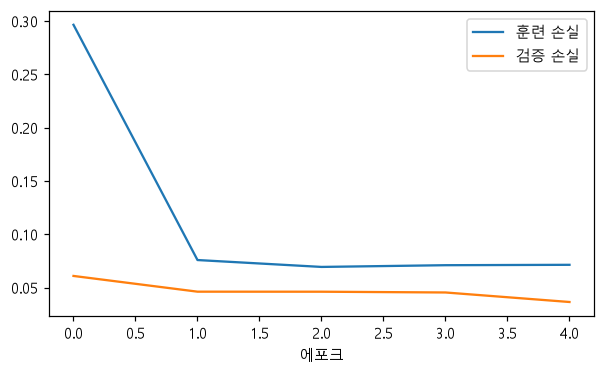

In [14]:
print(history.history.keys())    # 에포크별 손실 · 지표가 쌓여 있음
plt.plot(history.history["loss"], label="훈련 손실")
plt.plot(history.history["val_loss"], label="검증 손실")
plt.xlabel("에포크"); plt.legend(); plt.show()

In [15]:
loss_and_metrics = model.evaluate(val_inputs, val_targets, batch_size=128, verbose=0)   # 평가
print("검증 손실, 정확도:", loss_and_metrics)

predictions = model.predict(val_inputs, batch_size=128, verbose=0)                    # 사용
print(predictions[:5])

검증 손실, 정확도: [0.036530233919620514, 1.0]
[[ 0.67477316]
 [-0.4138842 ]
 [ 1.1705348 ]
 [-0.11963329]
 [ 0.6468539 ]]


## 정리

| | 그레이디언트 | 상태 |
|---|---|---|
| 텐서플로 | `GradientTape`로 **기록** | `tf.Variable` + `assign` |
| 파이토치 | 텐서가 **역추적**, `.grad`에 누적 | `requires_grad` 텐서, 직접 비우기 |
| JAX | `jax.grad`로 **함수 변환** | 없음 → 반환값으로 들고 다님 |
| 케라스 | 위 셋 중 하나를 백엔드로 | `compile → fit → evaluate → predict` |

*결국, 길만 다르고 답은 같다. 케라스면 갈아타기 쉽다.

👉 해 볼 것: 0번 셀에서 백엔드를 `"torch"`나 `"tensorflow"`로 바꾸고 커널 재시작 → 4 · 5절이 그대로 도는지 확인하기